# Bounds under sample selection: Lee bounds

A job-training programme is randomised. Its effect on employment is easy to estimate. Its effect on
*wages* is not, because wages are observed only for the employed. If training helps some people find
work who would otherwise not have worked, the employed treated and the employed controls are
different groups. Their wage gap mixes the effect of training with the selection of who works. The
same problem arises with test scores under attrition and survey outcomes under non-response.

Lee (2009) bounds the effect for the **always-employed**, the units who would work with or without
training. The only assumption is monotonicity: training only raises (or only lowers) employment.
Then all employed controls are always-employed. Among the employed treated, a share

$$
q = \frac{p_1 - p_0}{p_1}
$$

($p_d$ = employment rate in arm $d$) works only because of training. Dropping the top or the bottom
$q$ of the treated wages gives the most pessimistic and the most optimistic comparison. The bounds
are sharp: no tighter bounds follow from these assumptions. `dml_rs.LeeBounds` computes them, with
covariate cells to tighten them, bootstrap standard errors and the Imbens–Manski confidence interval.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dml_rs

pd.set_option("display.precision", 3)


def simulate(n, rng, boost=0.6):
    # Randomised training D; employment S rises with training (monotone);
    # log wages are observed only for the employed.
    region = rng.integers(0, 4, size=n)
    ability = 0.5 * rng.normal(size=n) + 0.6 * region
    D = (rng.random(n) < 0.5).astype(float)
    v = rng.normal(size=n)
    S0 = (0.3 * ability + v > 0.2).astype(float)
    S1 = (0.3 * ability + v + boost > 0.2).astype(float)
    W0 = 2 + 0.5 * ability + 0.5 * rng.normal(size=n)
    W1 = W0 + 0.2  # training raises log wages by 0.2
    S = np.where(D == 1, S1, S0)
    y = np.where(S == 1, np.where(D == 1, W1, W0), np.nan)
    return y, D, S, region


y, d, s, region = simulate(6000, np.random.default_rng(0))
print(
    f"employment rate: treated {s[d == 1].mean():.3f},",
    f"controls {s[d == 0].mean():.3f}"
)
print(
    "naive wage gap among the employed:",
    f"{np.nanmean(y[d == 1]) - np.nanmean(y[d == 0]):.3f} (true effect 0.2)"
)

employment rate: treated 0.736, controls 0.526
naive wage gap among the employed: 0.146 (true effect 0.2)


Training raises employment by about 20 points. The people it brings into work have lower ability
than those who work anyway, so the naive comparison understates the true wage effect of 0.2.

## The bounds

`fit` takes the outcome (any value, here NaN, where it is not observed), the treatment and the
selection indicator:

In [2]:
lee = dml_rs.LeeBounds().fit(y, d, s)
lee.summary.T

,Lee bounds
lower bound,-0.163
upper bound,0.455
se lower,0.027
se upper,0.026
95% CI lower,-0.207
95% CI upper,0.498
trimmed share,0.285


About 29% of the employed treated are trimmed. The bounds contain the true effect, and they are wide:
trimming that share from one tail or the other moves the treated wage mean a lot. `confint_` is the
Imbens–Manski interval. It covers the *effect*, not the whole identified set, with 95% probability,
so it is only slightly wider than the bounds.

## Tightening with covariates

If a discrete covariate predicts wages, compute the bounds within each of its cells and average them.
The trimming then removes units that are low or high *relative to their cell*, which is less
extreme, and the bounds become narrower (Lee 2009, Section 4). Pass the cells as `strata`:

In [3]:
lee_cells = dml_rs.LeeBounds().fit(y, d, s, strata=region)
pd.DataFrame(
    {"no covariates": lee.bounds_, "within regions": lee_cells.bounds_},
    index=["lower", "upper"],
)

,no covariates,within regions
lower,-0.163,-0.059
upper,0.455,0.461


The lower bound rises from about −0.16 to about −0.06. Region predicts ability, so the units trimmed
within each region are closer to the always-employed than the units trimmed overall.

## Width depends on the selection effect

The bounds are only as narrow as the treatment's effect on selection allows. With no effect on
employment, $q = 0$ and the bounds collapse to the simple wage comparison. Vary the employment
effect of training:

In [4]:
rows = []
for boost in [0.0, 0.1, 0.2, 0.4, 0.6, 0.8]:
    yb, db, sb, rb = simulate(6000, np.random.default_rng(1), boost=boost)
    fit = dml_rs.LeeBounds(n_boot=200).fit(yb, db, sb, strata=rb)
    rows.append(
        {
            "employment effect": sb[db == 1].mean() - sb[db == 0].mean(),
            "trimmed share": fit.trimming_,
            "lower": fit.lower_,
            "upper": fit.upper_,
            "CI lower": fit.confint_[0],
            "CI upper": fit.confint_[1],
        }
    )
widths = pd.DataFrame(rows)
widths

,employment effect,trimmed share,lower,upper,CI lower,CI upper
0,0.010,0.018,0.175,0.267,0.135,0.306
1,0.049,0.086,0.119,0.308,0.072,0.352
2,0.084,0.139,0.068,0.352,0.024,0.395
3,0.163,0.238,-0.015,0.430,-0.053,0.468
4,0.222,0.299,-0.060,0.481,-0.097,0.518
5,0.274,0.344,-0.097,0.514,-0.132,0.549


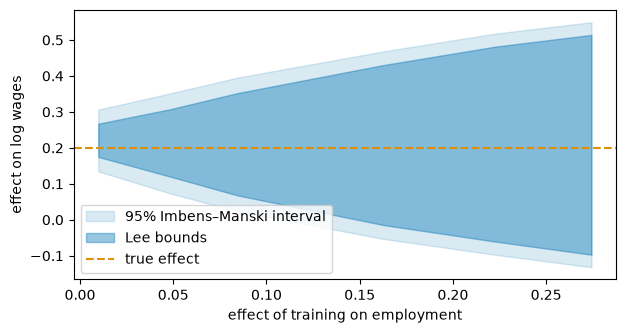

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.fill_between(
    widths["employment effect"],
    widths["CI lower"],
    widths["CI upper"],
    color="#0173B2",
    alpha=0.15,
    label="95% Imbens–Manski interval",
)
ax.fill_between(
    widths["employment effect"],
    widths["lower"],
    widths["upper"],
    color="#0173B2",
    alpha=0.4,
    label="Lee bounds",
)
ax.axhline(0.2, color="#DE8F05", ls="--", label="true effect")
ax.set_xlabel("effect of training on employment")
ax.set_ylabel("effect on log wages")
ax.legend(loc="lower left");

## Coverage

Over 200 simulated experiments with 2,000 people each, the Imbens–Manski interval contains the true
effect:

In [6]:
hits = {"no covariates": 0, "within regions": 0}
for r in range(200):
    yr, dr, sr, rr = simulate(2000, np.random.default_rng(100 + r))
    for name, strata in [("no covariates", None), ("within regions", rr)]:
        lo, hi = (
            dml_rs.LeeBounds(n_boot=200, random_state=r)
            .fit(yr, dr, sr, strata=strata)
            .confint_
        )
        hits[name] += lo <= 0.2 <= hi
pd.Series(hits) / 200

no covariates     1.0
within regions    1.0
dtype: float64

Here the true effect lies well inside the bounds, so the interval covers it every time. Its nominal
95% applies at the worst case, an effect at one end of the identified set.

## Summary

- `LeeBounds` bounds the effect of a randomised treatment for the units whose outcome is observed
  under either treatment, when the treatment changes who is observed. It assumes only monotonicity of
  selection.
- `strata` (discrete covariate cells, any labels) tighten the bounds when the cells predict the
  outcome.
- `bounds_`, `se_` (bootstrap, units resampled within arms) and `confint_` (Imbens–Manski) summarise
  the result. `trimmed_treated_` says which arm was trimmed.